![Johnson & Johnson MedTech Logo](https://raw.githubusercontent.com/Forage-Simulations/Johnson-Johnson-Robotics-Controls/main/github_assets.png)


# Robotic Arm Design Simulation

### Objective
This notebook helps simulate the impact of design modifications on a robotic arm’s performance. You will:

- Test design modifications for improving response time and durability.
- Input efficiency and reinforcement factors to assess their impact.
- Visualize simulation results for response time and durability metrics.
- Document findings to support your design proposal.

### Instructions
1. **Run Setup Cells**: Load libraries and define functions necessary for simulations.
2. **Input Factors**: Enter efficiency and reinforcement factors to simulate improvements.
3. **Analyze Results**: Compare original and improved metrics using the visual output.
4. **Document Findings**: Record your observations to support your design proposal.

Ensure you use the **Design Proposal Template** to document your findings.


In [2]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -------------- ------------------------- 3.4/9.5 MB 16.3 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.5 MB 15.9 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 14.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 13.7 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   --------------------------------- ------ 2.1/2.5 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 8.6 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ------------- -------------------------- 2.4/7.2 MB 11.8 MB/s eta 0:00:01
   ---------------------------- ----------- 5.2/7.2 MB 13.5 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 13.7 MB/s  0:

In [1]:
# Import required libraries
import numpy as np  # For numerical calculations
import matplotlib.pyplot as plt  # For data visualization

# Ensure the necessary libraries are installed
try:
    import numpy
    import matplotlib
except ImportError as e:
    print(f"Missing library: {e}. Please install it using 'pip install numpy matplotlib'.")


Matplotlib is building the font cache; this may take a moment.


In [2]:
# Function to simulate response time improvements
def simulate_response_time(base_time, efficiency_factor):
    """Calculate the new response time based on efficiency improvements."""
    return base_time * (1 - efficiency_factor)

# Function to simulate durability improvements
def simulate_durability(base_durability, reinforcement_factor):
    """Calculate the new durability score based on reinforcement."""
    return base_durability + (base_durability * reinforcement_factor)


In [3]:
# Example Base Metrics
base_response_time = 0.20  # in seconds
base_durability = 75       # durability score out of 100

# User Inputs with Validation
while True:
    try:
        efficiency_factor = float(input("Enter efficiency improvement factor (between 0 and 1, e.g., 0.15 for 15%): "))
        if 0 <= efficiency_factor <= 1:
            break
        else:
            print("Please enter a value between 0 and 1.")
    except ValueError:
        print("Invalid input. Please enter a numerical value.")

while True:
    try:
        reinforcement_factor = float(input("Enter durability reinforcement factor (between 0 and 1, e.g., 0.10 for 10%): "))
        if 0 <= reinforcement_factor <= 1:
            break
        else:
            print("Please enter a value between 0 and 1.")
    except ValueError:
        print("Invalid input. Please enter a numerical value.")


Tested 10201 combinations
1734 combinations stay within the design limits

Top 10 valid combinations:
Efficiency  Reinforce  Resp. time  Durability   Score
      0.50       0.33      0.100s       99.75   0.830
      0.49       0.33      0.102s       99.75   0.820
      0.50       0.32      0.100s       99.00   0.820
      0.48       0.33      0.104s       99.75   0.810
      0.49       0.32      0.102s       99.00   0.810
      0.50       0.31      0.100s       98.25   0.810
      0.47       0.33      0.106s       99.75   0.800
      0.48       0.32      0.104s       99.00   0.800
      0.49       0.31      0.102s       98.25   0.800
      0.50       0.30      0.100s       97.50   0.800

Most effective combination: efficiency = 0.5, reinforcement = 0.33


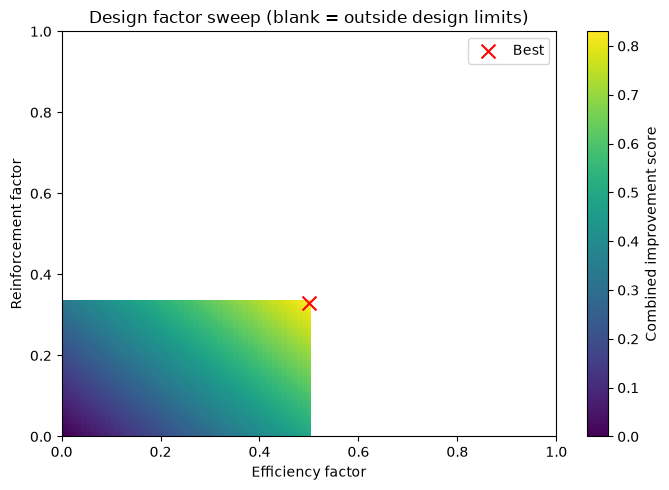

In [6]:
# Example Base Metrics
base_response_time = 0.20  # in seconds
base_durability = 75       # durability score out of 100

# Design limits for a valid result
MIN_RESPONSE_TIME = 0.10   # target response time from Task 1 (seconds)
MAX_DURABILITY = 100       # durability score cannot exceed the 100-point scale

# Test every factor from 0.00 to 1.00 in 0.01 steps (101 x 101 = 10,201 combinations)
factors = np.round(np.arange(0, 101) / 100, 2)

results = []
for e in factors:
    for r in factors:
        rt = simulate_response_time(base_response_time, e)
        dur = simulate_durability(base_durability, r)
        valid = rt >= MIN_RESPONSE_TIME - 1e-9 and dur <= MAX_DURABILITY + 1e-9
        # Score: response time reduction % + durability gain %, weighted equally
        score = (base_response_time - rt) / base_response_time + (dur - base_durability) / base_durability
        results.append((e, r, rt, dur, score, valid))

print(f"Tested {len(results)} combinations")
valid_results = [res for res in results if res[5]]
print(f"{len(valid_results)} combinations stay within the design limits")

# Best = highest score; ties go to the smallest factors (least design change)
valid_results.sort(key=lambda res: (-round(res[4], 6), res[0] + res[1]))

print("\nTop 10 valid combinations:")
print(f"{'Efficiency':>10} {'Reinforce':>10} {'Resp. time':>11} {'Durability':>11} {'Score':>7}")
for e, r, rt, dur, score, _ in valid_results[:10]:
    print(f"{e:>10.2f} {r:>10.2f} {rt:>10.3f}s {dur:>11.2f} {score:>7.3f}")

# Use the best combination for the rest of the notebook
efficiency_factor, reinforcement_factor = valid_results[0][0], valid_results[0][1]
print(f"\nMost effective combination: efficiency = {efficiency_factor}, reinforcement = {reinforcement_factor}")

# Heatmap of the score across all combinations (invalid ones greyed out)
score_grid = np.full((len(factors), len(factors)), np.nan)
for e, r, rt, dur, score, valid in results:
    if valid:
        score_grid[int(round(r * 100)), int(round(e * 100))] = score

plt.figure(figsize=(7, 5))
plt.imshow(score_grid, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
plt.colorbar(label="Combined improvement score")
plt.scatter(efficiency_factor, reinforcement_factor, color="red", marker="x", s=100, label="Best")
plt.xlabel("Efficiency factor")
plt.ylabel("Reinforcement factor")
plt.title("Design factor sweep (blank = outside design limits)")
plt.legend()
plt.tight_layout()
plt.show()


In [4]:
# Simulations
new_response_time = simulate_response_time(base_response_time, efficiency_factor)
new_durability = simulate_durability(base_durability, reinforcement_factor)

# Output Results
print("\nSimulation Results:")
print(f"Original Response Time: {base_response_time} seconds")
print(f"New Response Time: {round(new_response_time, 3)} seconds")
print(f"Original Durability Score: {base_durability}")
print(f"New Durability Score: {round(new_durability, 2)}")



Simulation Results:
Original Response Time: 0.2 seconds
New Response Time: 0.1 seconds
Original Durability Score: 75
New Durability Score: 112.5


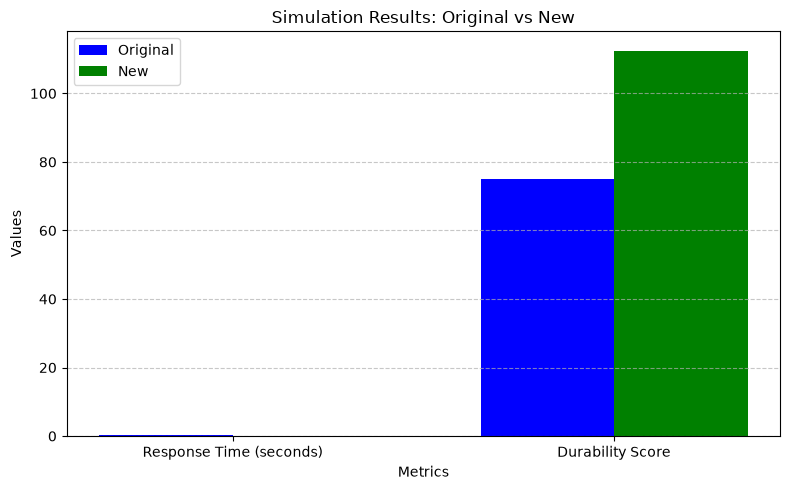

In [5]:
# Visual Feedback
metrics = ["Response Time (seconds)", "Durability Score"]
original_values = [base_response_time, base_durability]
new_values = [new_response_time, new_durability]

plt.figure(figsize=(8, 5))
x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, original_values, width, label='Original', color='blue')
plt.bar(x + width/2, new_values, width, label='New', color='green')

plt.xlabel("Metrics")
plt.ylabel("Values")
plt.title("Simulation Results: Original vs New")
plt.xticks(x, metrics)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
### Observations and Results

Record your observations from the simulation below:

#### Initial Metrics:
- Response Time: 0.20 seconds
- Durability Score: 75

#### Improved Metrics:
- Response Time: [Enter improved value]
- Durability Score: [Enter improved value]

#### Key Insights:
1. How did the efficiency improvement factor impact response time?
2. How did the reinforcement factor affect durability?
3. Were there any trade-offs between responsiveness and durability?

#### Conclusion:
Summarize the impact of your design modifications and suggest next steps for further improvements.
